# 04 — Prédiction du type de trafic : Random Forest Regressor

**Responsable : Membre 4** · Cible : `type` (10 classes) encodée en **code ordinal** · Entrée : `data/processed/*` (notebook 01)

## Pourquoi une *régression* pour une cible nominale ?
Le sujet impose des **régresseurs** pour prédire le type. `type` est nominal : on lui donne donc un **code ordinal** défini dans `ml_utils.TYPE_ORDER`
(normal → reconnaissance → déni de service → attaques web → malware → interception), choisi a priori. **Attention** : l'étude de sensibilité du notebook 04 (§1) montre que cet ordre n'apporte pas de gain mesurable face à un ordre alphabétique ou aléatoire ; le choix d'ordre reste donc arbitraire. Le modèle prédit un **nombre** ; on retrouve la classe par **décodage** (arrondi, puis seuils optimisés).

## Workflow
1. Encodage ordinal de la cible et **sensibilité à l'ordre** choisi (sur ce notebook)
2. **Baseline**
3. **Équilibrage** : pondération des échantillons (`sample_weight`) comparée en validation croisée
4. **Réglage des hyper-paramètres** (recherche aléatoire, CV stratifiée sur `type`)
5. Nombre d'arbres vs erreur
6. Évaluation en validation : métriques de régression **et** de classification après décodage
7. **Calibration du décodage** : seuils entre classes optimisés sur la validation
8. **Évaluation finale unique sur le test**
9. Interprétation (importances, permutation) et analyse des erreurs par type
10. Sauvegarde pour le tableau comparatif (notebook 06)

## Métriques
- **Régression** (sur le code brut) : MAE, RMSE, R²
- **Après décodage** : accuracy, balanced accuracy, **F1 macro** (important : `mitm` ne pèse que 0,6 % des lignes), part des erreurs d'au plus **1 classe**

In [1]:
import sys, time, warnings
sys.path.append("../src")
import numpy as np, pandas as pd, joblib
import matplotlib.pyplot as plt, seaborn as sns
import ml_utils as U
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, ParameterSampler, train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore"); sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.float_format", "{:.4f}".format); pd.set_option("display.max_columns", 40)
RS = U.RANDOM_STATE; K = len(U.TYPE_ORDER)
cfg = U.load_config(); NUM, CAT = cfg["numeric_cols"], cfg["categorical_cols"]
X_train, y_tr = U.load_split("train"); X_valid, y_va = U.load_split("valid"); X_test, y_te = U.load_split("test")
ytr, yva, yte = y_tr["type_code"].to_numpy(), y_va["type_code"].to_numpy(), y_te["type_code"].to_numpy()
print({"train": X_train.shape, "valid": X_valid.shape, "test": X_test.shape})
display(pd.DataFrame({"code": range(K), "type": U.TYPE_ORDER, "effectif train": np.bincount(ytr, minlength=K)}).set_index("code").T)

{'train': (110132, 33), 'valid': (36711, 33), 'test': (36711, 33)}


code,0,1,2,3,4,5,6,7,8,9
type,normal,scanning,dos,ddos,password,injection,xss,backdoor,ransomware,mitm
effectif train,25161,11169,8805,11991,11908,11975,8713,11226,8560,624


## 1. Sensibilité à l'ordre d'encodage
Une régression suppose que la distance entre codes a un sens. On compare l'ordre **documenté** (`TYPE_ORDER`), l'ordre **alphabétique** et un ordre **aléatoire**
avec un petit Random Forest (60 arbres, 30 000 lignes), évalué en validation. Seule l'exactitude après arrondi est comparable d'un encodage à l'autre.

In [2]:
rng = np.random.default_rng(RS)
orders = {"Documenté (TYPE_ORDER)": U.TYPE_ORDER, "Alphabétique": sorted(U.TYPE_ORDER), "Aléatoire": list(rng.permutation(U.TYPE_ORDER))}
small = X_train.sample(30000, random_state=RS).index; rows = []
for nm, order in orders.items():
    mp = {t: i for i, t in enumerate(order)}
    a, b = y_tr["type"].map(mp).to_numpy()[small], y_va["type"].map(mp).to_numpy()
    m = Pipeline([("pre", U.make_preprocessor(NUM, CAT, scale=False)), ("model", RandomForestRegressor(n_estimators=60, min_samples_leaf=2, n_jobs=-1, random_state=RS))]).fit(X_train.loc[small], a)
    rows.append({"encodage": nm, **U.regression_metrics(b, m.predict(X_valid), K)})
enc = pd.DataFrame(rows).set_index("encodage"); display(enc.round(4))

,mae,rmse,r2,accuracy,balanced_accuracy,f1_macro,within_1_class
encodage,,,,,,,
Documenté (TYPE_ORDER),0.0739,0.4482,0.9728,0.9656,0.8795,0.8821,0.9841
Alphabétique,0.1040,0.5510,0.9610,0.9566,0.9105,0.8989,0.9752
Aléatoire,0.0629,0.3686,0.9821,0.9662,0.9074,0.9073,0.9873


## 2. Pipeline et pondération
Pas de standardisation (`scale=False`) : les arbres sont invariants aux transformations monotones ; `log1p` est néanmoins conservé pour la lisibilité des importances.
Les **poids** compensent le déséquilibre (§équilibrage) : `balanced` = n / (K × effectif de la classe) ; `racine` = sa racine carrée (correction adoucie).

In [3]:
def make_model(**p):
    return Pipeline([("pre", U.make_preprocessor(NUM, CAT, scale=False)),
                     ("model", RandomForestRegressor(n_jobs=-1, random_state=RS, **p))])
cnt = np.bincount(ytr, minlength=K)
w_bal = (len(ytr) / (K * cnt))[ytr]; w_sqrt = np.sqrt(w_bal); w_sqrt = w_sqrt / w_sqrt.mean()
SCHEMES = {"Aucun": None, "Poids balanced": w_bal, "Poids racine (adouci)": w_sqrt}
print("Poids par classe (balanced) :", dict(zip(U.TYPE_ORDER, (len(ytr) / (K * cnt)).round(2))))
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RS)
sub = X_train.sample(40000, random_state=RS).index.to_numpy()      # sous-échantillon pour la CV / le réglage
Xs, ys, strat = X_train.loc[sub].reset_index(drop=True), ytr[sub], y_tr["type"].to_numpy()[sub]

def cv_eval(make, w=None, X=Xs, y=ys, strat_=strat):
    rows = []
    for tr, va in cv.split(X, strat_):
        t0 = time.time(); m = make()
        m.fit(X.iloc[tr], y[tr], model__sample_weight=None if w is None else w[tr]); fit_t = time.time() - t0
        rows.append({**U.regression_metrics(y[va], m.predict(X.iloc[va]), K), "fit_s": fit_t})
    return pd.DataFrame(rows).mean()

Poids par classe (balanced) : {'normal': np.float64(0.44), 'scanning': np.float64(0.99), 'dos': np.float64(1.25), 'ddos': np.float64(0.92), 'password': np.float64(0.92), 'injection': np.float64(0.92), 'xss': np.float64(1.26), 'backdoor': np.float64(0.98), 'ransomware': np.float64(1.29), 'mitm': np.float64(17.65)}


## 3. Baseline
Random Forest Regressor avec hyper-paramètres par défaut, sans pondération.

In [4]:
t0 = time.time(); base = make_model(n_estimators=100).fit(X_train, ytr); t_base = time.time() - t0
base_valid = U.regression_metrics(yva, base.predict(X_valid), K)
print(f"Temps : {t_base:.1f}s"); display(pd.Series(base_valid).to_frame("baseline (validation)").T.round(4))

Temps : 57.2s


,mae,rmse,r2,accuracy,balanced_accuracy,f1_macro,within_1_class
baseline (validation),0.0482,0.3635,0.9821,0.9772,0.9103,0.9230,0.9892


## 4. Équilibrage : pondération des échantillons
Les rééchantillonneurs classiques (SMOTE, sous-échantillonnage) travaillent sur des **classes** et ne s'appliquent pas à une cible continue.
Pour un régresseur, l'équivalent est `sample_weight` : la perte quadratique des classes rares est multipliée. Les trois schémas sont comparés en CV (poids appris **dans** chaque pli),
sur des métriques **non pondérées** pour que la comparaison reste honnête. Choix sur le **F1 macro**.

,mae,rmse,r2,accuracy,balanced_accuracy,f1_macro,within_1_class,fit_s
Aucun,0.0689,0.4396,0.9739,0.9675,0.8836,0.8881,0.9856,11.7866
Poids balanced,0.0712,0.4427,0.9736,0.9665,0.8814,0.8850,0.9851,11.3438
Poids racine (adouci),0.0694,0.4423,0.9736,0.9676,0.8831,0.8874,0.9859,11.6200


=> Schéma retenu : Aucun


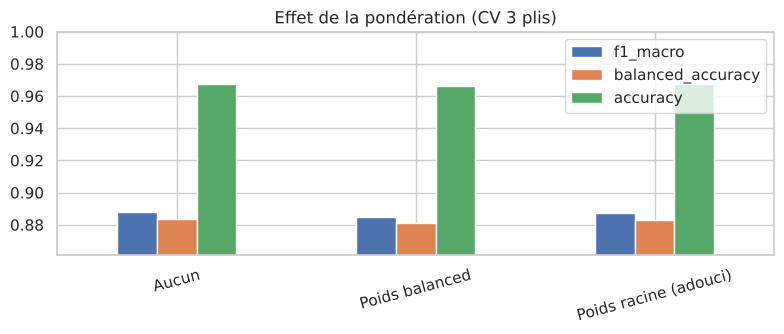

In [5]:
rows = {n: cv_eval(lambda: make_model(n_estimators=100), w) for n, w in SCHEMES.items()}
wtab = pd.DataFrame(rows).T; display(wtab[["mae", "rmse", "r2", "accuracy", "balanced_accuracy", "f1_macro", "within_1_class", "fit_s"]].round(4))
best_scheme = wtab["f1_macro"].idxmax(); w_best = SCHEMES[best_scheme]; print(f"=> Schéma retenu : {best_scheme}")
fig, ax = plt.subplots(figsize=(8, 3.5)); wtab[["f1_macro", "balanced_accuracy", "accuracy"]].plot(kind="bar", ax=ax); ax.set_ylim(wtab[["f1_macro", "balanced_accuracy", "accuracy"]].min().min() - .02, 1)
ax.set_title("Effet de la pondération (CV 3 plis)"); ax.tick_params(axis="x", rotation=15); plt.tight_layout(); U.savefig(fig, "04_weighting"); plt.show()

## 5. Réglage des hyper-paramètres
Recherche aléatoire (10 configurations × 3 plis) sur le sous-échantillon, avec le schéma de poids retenu. Classement par **RMSE** (perte native de la régression) ; le F1 macro est affiché en parallèle.

In [6]:
space = {"n_estimators": [100, 200], "max_depth": [None, 15, 25], "min_samples_leaf": [1, 2, 4, 8], "max_features": [0.3, 0.5, 1.0]}
fixed = {}
configs, rows = [], []
for i, p in enumerate(ParameterSampler(space, n_iter=10, random_state=RS)):
    p = {k: (v.item() if hasattr(v, "item") else v) for k, v in p.items()}
    r = cv_eval(lambda: make_model(**{**fixed, **p}), w_best); configs.append(p)
    rows.append({**{k: str(v) for k, v in p.items()}, "rmse": r["rmse"], "f1_macro": r["f1_macro"], "accuracy": r["accuracy"], "fit_s": r["fit_s"]})
    print(f"  [{i+1}/10] rmse={r['rmse']:.4f} f1_macro={r['f1_macro']:.4f}  {p}")
tuning = pd.DataFrame(rows).sort_values("rmse"); display(tuning.head(8).round(4))
best_params = configs[int(tuning.index[0])]; print("Meilleurs hyper-paramètres :", best_params)

  [1/10] rmse=0.4446 f1_macro=0.8621  {'n_estimators': 100, 'min_samples_leaf': 4, 'max_features': 0.3, 'max_depth': None}


  [2/10] rmse=0.4772 f1_macro=0.8561  {'n_estimators': 100, 'min_samples_leaf': 8, 'max_features': 0.5, 'max_depth': 25}


  [3/10] rmse=0.4450 f1_macro=0.8822  {'n_estimators': 100, 'min_samples_leaf': 2, 'max_features': 1.0, 'max_depth': None}


  [4/10] rmse=0.4144 f1_macro=0.8846  {'n_estimators': 100, 'min_samples_leaf': 1, 'max_features': 0.3, 'max_depth': None}


  [5/10] rmse=0.4508 f1_macro=0.8605  {'n_estimators': 100, 'min_samples_leaf': 4, 'max_features': 0.3, 'max_depth': 15}


  [6/10] rmse=0.4247 f1_macro=0.8723  {'n_estimators': 100, 'min_samples_leaf': 2, 'max_features': 0.3, 'max_depth': 25}


... (2 outputs left out)

  [9/10] rmse=0.4409 f1_macro=0.8660  {'n_estimators': 100, 'min_samples_leaf': 4, 'max_features': 0.5, 'max_depth': None}


  [10/10] rmse=0.4842 f1_macro=0.8532  {'n_estimators': 100, 'min_samples_leaf': 8, 'max_features': 0.3, 'max_depth': 25}


,n_estimators,min_samples_leaf,max_features,max_depth,rmse,f1_macro,accuracy,fit_s
3,100,1,0.3,None,0.4144,0.8846,0.9668,4.3713
5,100,2,0.3,25,0.4247,0.8723,0.9628,4.2542
6,100,2,0.5,None,0.4258,0.8773,0.9640,6.5930
7,100,2,0.5,15,0.4282,0.8667,0.9624,6.0583
8,100,4,0.5,None,0.4409,0.8660,0.9598,6.3195
0,100,4,0.3,None,0.4446,0.8621,0.9575,4.0859
2,100,2,1.0,None,0.4450,0.8822,0.9659,11.4213
4,100,4,0.3,15,0.4508,0.8605,0.9567,3.8846


Meilleurs hyper-paramètres : {'n_estimators': 100, 'min_samples_leaf': 1, 'max_features': 0.3, 'max_depth': None}


## 6. Modèle final et courbe « nombre d'arbres → erreur »

Entraînement final : 41.0s


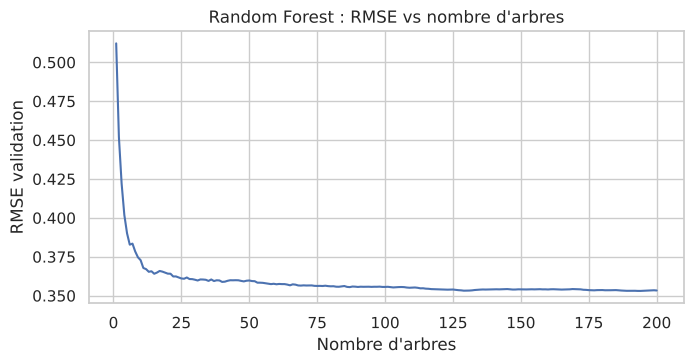

In [7]:
best_params["n_estimators"] = max(best_params.get("n_estimators", 200), 200)
w_full = w_best
t0 = time.time(); final = make_model(**best_params).fit(X_train, ytr, model__sample_weight=w_full); t_fit = time.time() - t0; print(f"Entraînement final : {t_fit:.1f}s")
Xv_t = final.named_steps["pre"].transform(X_valid); trees = final.named_steps["model"].estimators_
cum = np.cumsum(np.array([t.predict(Xv_t.astype(np.float32)) for t in trees]), axis=0) / np.arange(1, len(trees) + 1)[:, None]
rm = np.sqrt(((cum - yva[None, :]) ** 2).mean(axis=1))
fig, ax = plt.subplots(figsize=(7, 3.8)); ax.plot(range(1, len(trees) + 1), rm); ax.set(xlabel="Nombre d'arbres", ylabel="RMSE validation", title="Random Forest : RMSE vs nombre d'arbres"); plt.tight_layout(); U.savefig(fig, "04_trees_curve"); plt.show()

## 7. Évaluation en validation

,mae,rmse,r2,accuracy,balanced_accuracy,f1_macro,within_1_class
train,0.0177,0.1270,0.9978,0.9890,0.9328,0.9476,0.9981
validation,0.0499,0.3533,0.9831,0.9761,0.9018,0.9118,0.9896


              precision    recall  f1-score   support

      normal      0.999     0.985     0.992      8387
    scanning      0.976     0.980     0.978      3723
         dos      0.967     0.972     0.970      2935
        ddos      0.977     0.969     0.973      3997
    password      0.964     0.989     0.976      3969
   injection      0.950     0.971     0.961      3992
         xss      0.960     0.953     0.957      2905
    backdoor      0.984     0.999     0.992      3742
  ransomware      0.979     0.998     0.988      2853
        mitm      0.933     0.202     0.332       208

    accuracy                          0.976     36711
   macro avg      0.969     0.902     0.912     36711
weighted avg      0.976     0.976     0.975     36711



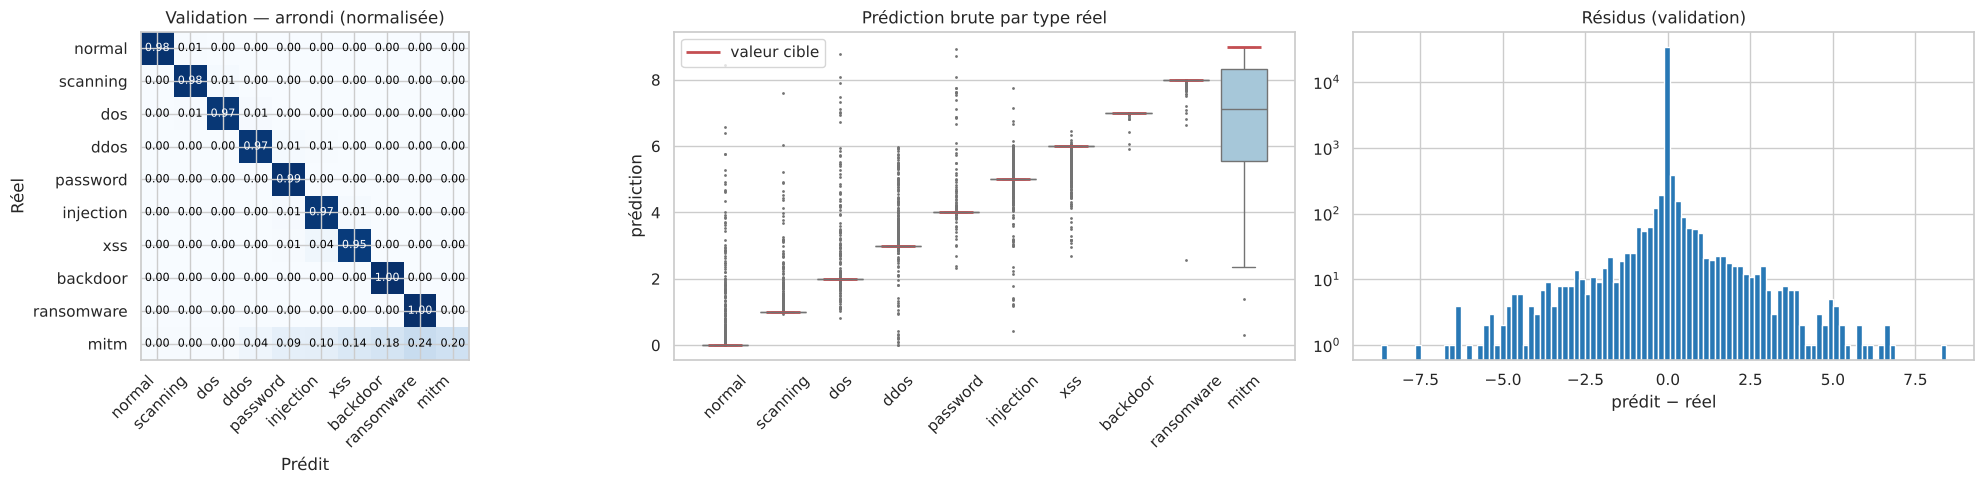

In [8]:
p_tr, p_va = final.predict(X_train), final.predict(X_valid)
rm_tr, rm_va = U.regression_metrics(ytr, p_tr, K), U.regression_metrics(yva, p_va, K)
display(pd.DataFrame({"train": rm_tr, "validation": rm_va}).T.round(4))
pred_va = np.clip(np.rint(p_va), 0, K - 1).astype(int)
print(classification_report(yva, pred_va, target_names=U.TYPE_ORDER, digits=3, zero_division=0))
fig, axes = plt.subplots(1, 3, figsize=(21, 5))
U.plot_confusion(confusion_matrix(yva, pred_va, labels=range(K)), U.TYPE_ORDER, "Validation — arrondi (normalisée)", ax=axes[0], normalize=True)
sns.boxplot(x=pd.Categorical(y_va["type"], U.TYPE_ORDER), y=p_va, ax=axes[1], fliersize=1, color="#9ecae1"); axes[1].plot(range(K), range(K), "r_", ms=25, mew=2, label="valeur cible")
axes[1].set(title="Prédiction brute par type réel", xlabel="", ylabel="prédiction"); axes[1].tick_params(axis="x", rotation=45); axes[1].legend()
axes[2].hist(p_va - yva, bins=100, color="#2878b5"); axes[2].set(title="Résidus (validation)", xlabel="prédit − réel", yscale="log")
plt.tight_layout(); U.savefig(fig, "04_valid_eval"); plt.show()

## 8. Calibration du décodage (seuils entre classes)
L'arrondi place les frontières à 0,5 ; 1,5 ; … Rien ne garantit qu'elles soient optimales (classes rares, erreurs asymétriques).
On cherche donc les **9 seuils** qui maximisent le F1 macro **sur la validation**, par descente de coordonnées, puis on les applique tels quels au test.

In [9]:
cuts, f1_cut = U.optimize_cutpoints(p_va, yva, K)
print("Seuils optimisés :", cuts.round(3)); print("Seuils par défaut:", (np.arange(K - 1) + .5))
pv_round = U.decode_with_cuts(p_va, np.arange(K - 1) + .5); pv_cut = U.decode_with_cuts(p_va, cuts)
cmp_ = pd.DataFrame({"arrondi": U.regression_metrics_from_classes(yva, p_va, pv_round, K), "seuils optimisés": U.regression_metrics_from_classes(yva, p_va, pv_cut, K)}).T
display(cmp_[["accuracy", "balanced_accuracy", "f1_macro", "within_1_class"]].round(4))

Seuils optimisés : [0.982 1.908 2.354 3.946 4.228 5.307 6.349 7.5   8.001]
Seuils par défaut: [0.5 1.5 2.5 3.5 4.5 5.5 6.5 7.5 8.5]


,accuracy,balanced_accuracy,f1_macro,within_1_class
arrondi,0.9761,0.9018,0.9118,0.9896
seuils optimisés,0.9794,0.9169,0.9302,0.9897


## 9. Évaluation finale sur le test (une seule fois)

,mae,rmse,r2,accuracy,balanced_accuracy,f1_macro,within_1_class
arrondi,0.0478,0.3485,0.9836,0.9774,0.9037,0.9140,0.9902
seuils optimisés (valid),0.0478,0.3485,0.9836,0.9800,0.9195,0.9335,0.9903


              precision    recall  f1-score   support

      normal      0.999     0.989     0.994      8387
    scanning      0.976     0.990     0.983      3723
         dos      0.987     0.962     0.974      2935
        ddos      0.967     0.976     0.972      3997
    password      0.989     0.984     0.987      3970
   injection      0.957     0.968     0.963      3992
         xss      0.954     0.976     0.965      2904
    backdoor      0.982     0.998     0.990      3742
  ransomware      0.988     0.999     0.993      2853
        mitm      0.961     0.351     0.514       208

    accuracy                          0.980     36711
   macro avg      0.976     0.919     0.933     36711
weighted avg      0.980     0.980     0.979     36711



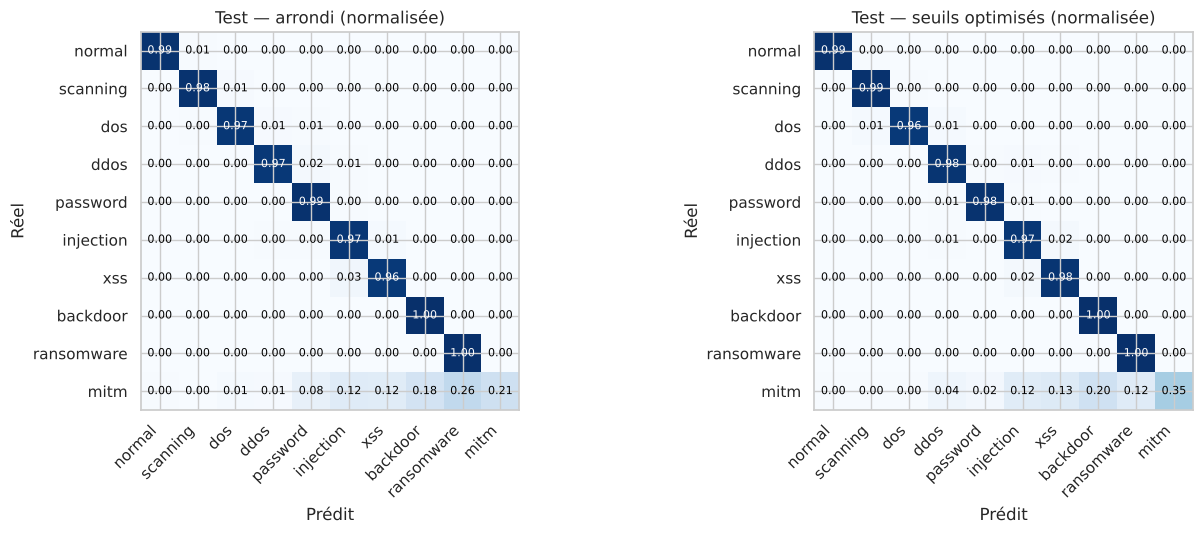

In [10]:
p_te = final.predict(X_test)
pt_round, pt_cut = U.decode_with_cuts(p_te, np.arange(K - 1) + .5), U.decode_with_cuts(p_te, cuts)
test_tbl = pd.DataFrame({"arrondi": U.regression_metrics_from_classes(yte, p_te, pt_round, K), "seuils optimisés (valid)": U.regression_metrics_from_classes(yte, p_te, pt_cut, K)}).T
display(test_tbl[["mae", "rmse", "r2", "accuracy", "balanced_accuracy", "f1_macro", "within_1_class"]].round(4))
print(classification_report(yte, pt_cut, target_names=U.TYPE_ORDER, digits=3, zero_division=0))
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
U.plot_confusion(confusion_matrix(yte, pt_round, labels=range(K)), U.TYPE_ORDER, "Test — arrondi (normalisée)", ax=axes[0], normalize=True)
U.plot_confusion(confusion_matrix(yte, pt_cut, labels=range(K)), U.TYPE_ORDER, "Test — seuils optimisés (normalisée)", ax=axes[1], normalize=True)
plt.tight_layout(); U.savefig(fig, "04_test_confusions"); plt.show()

## 10. Interprétation et analyse des erreurs

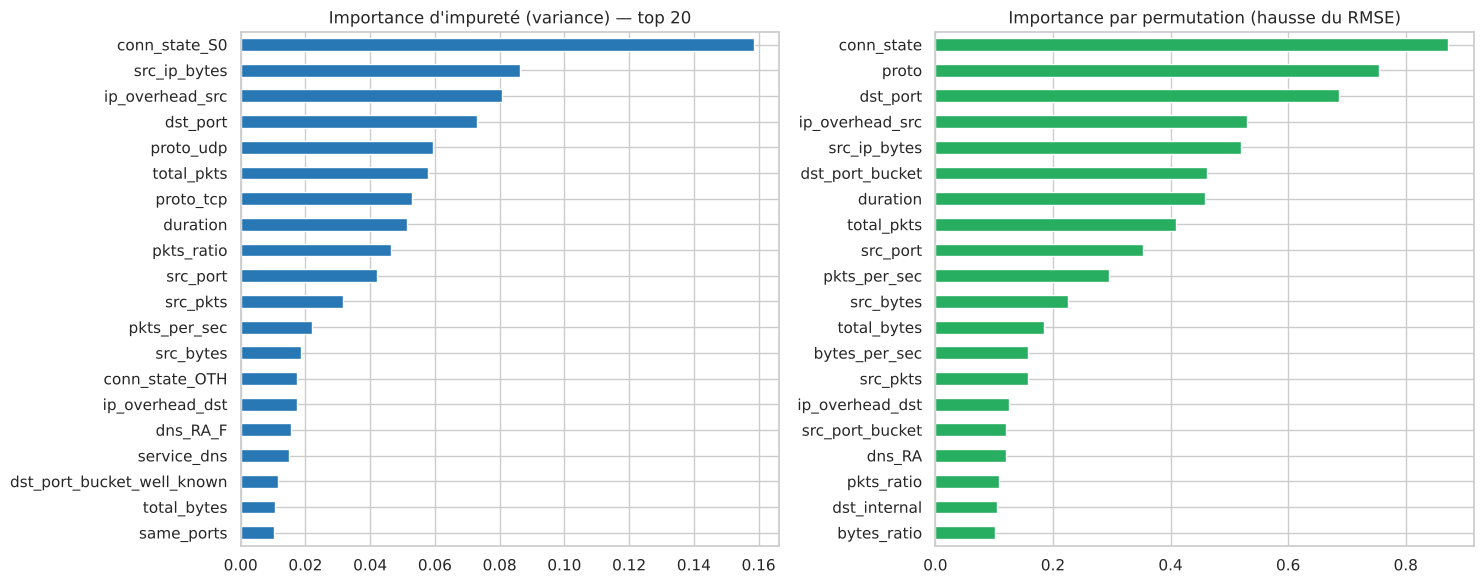

In [11]:
imp = pd.Series(final.named_steps["model"].feature_importances_, index=U.feature_names(final.named_steps["pre"])).sort_values(ascending=False)
imp_title = "Importance d'impureté (variance) — top 20"
sidx = X_valid.sample(6000, random_state=RS).index
pi = permutation_importance(final, X_valid.loc[sidx], yva[sidx.to_numpy()], scoring="neg_root_mean_squared_error", n_repeats=3, random_state=RS, n_jobs=1)
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
imp.head(20).iloc[::-1].plot(kind="barh", ax=axes[0], color="#2878b5"); axes[0].set_title(imp_title)
pd.Series(pi.importances_mean, index=X_valid.columns).sort_values().tail(20).plot(kind="barh", ax=axes[1], color="#27ae60"); axes[1].set_title("Importance par permutation (hausse du RMSE)")
plt.tight_layout(); U.savefig(fig, "04_importances"); plt.show()

,n,MAE,rappel,erreur_>1_classe
type,,,,
normal,8387.0000,0.0346,0.9894,0.0064
scanning,3723.0000,0.0354,0.9898,0.0059
dos,2935.0000,0.0672,0.9622,0.0133
ddos,3997.0000,0.0610,0.9765,0.0175
password,3970.0000,0.0168,0.9844,0.0030
injection,3992.0000,0.0504,0.9684,0.0108
xss,2904.0000,0.0568,0.9759,0.0014
backdoor,3742.0000,0.0033,0.9984,0.0005
ransomware,2853.0000,0.0038,0.9989,0.0000


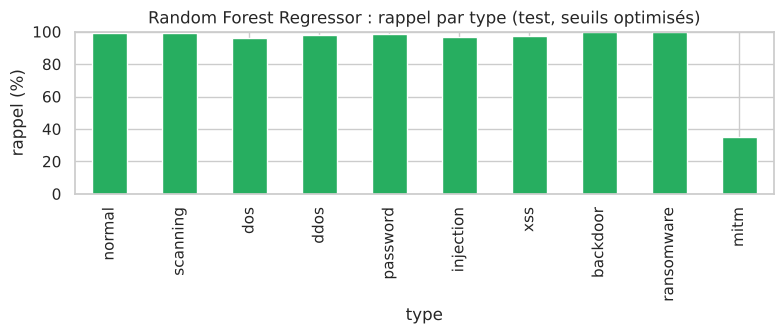

In [12]:
d = pd.DataFrame({"type": y_te["type"].to_numpy(), "code": yte, "pred": p_te, "cls": pt_cut})
by_type = d.groupby("type").apply(lambda g: pd.Series({"n": len(g), "MAE": np.abs(g.pred - g.code).mean(), "rappel": (g.cls == g.code).mean(), "erreur_>1_classe": (np.abs(g.cls - g.code) > 1).mean()})).loc[U.TYPE_ORDER]
display(by_type.round(4))
fig, ax = plt.subplots(figsize=(8, 3.5)); by_type["rappel"].mul(100).plot(kind="bar", ax=ax, color="#27ae60"); ax.set(ylabel="rappel (%)", title="Random Forest Regressor : rappel par type (test, seuils optimisés)"); ax.set_ylim(0, 100)
plt.tight_layout(); U.savefig(fig, "04_recall_by_type"); plt.show()

## 11. Sauvegarde

In [13]:
joblib.dump(final, U.MODEL_DIR / "rf_type_regressor.joblib", compress=3)
U.save_result("04_rf_regressor", {"task": "Prédiction du type", "model": "Random Forest Regressor", "weighting": best_scheme, "params": best_params, "cutpoints": cuts.tolist(), "fit_time_s": t_fit,
    "valid_f1_macro_cuts": f1_cut, "test_rounded": {k: float(v) for k, v in test_tbl.loc["arrondi"].items()},
    "test": {k: float(v) for k, v in test_tbl.loc["seuils optimisés (valid)"].items()}, "weighting_cv": wtab.round(5).to_dict("index"), "recall_by_type": by_type["rappel"].to_dict()})
print("Modèle et résultats sauvegardés.")

Modèle et résultats sauvegardés.


## Conclusion (Random Forest Regressor — prédiction du type)

- La cible nominale est traitée comme un **code ordinal** documenté ; l'ordre d'encodage influence les résultats (§1).
- L'équilibrage passe par `sample_weight`, choisi en **validation croisée** sur le F1 macro.
- Les **seuils de décodage** sont calibrés sur la validation ; le test n'est lu qu'une fois.
- Limite à assumer : un **classifieur multi-classes** serait plus naturel pour un type nominal ; l'étude de sensibilité (notebook 04, §1) n'a pas montré que l'ordre choisi soit meilleur qu'un ordre aléatoire, ce qui renforce cette recommandation.
- Valeurs chiffrées : §9 (test) et notebook 06.